# Exploratory Data Analysis

This notebook explores the processed customer, subscription, viewing, payment, support, feedback, and churn datasets. It produces **23 visualizations** across customer composition, plan/revenue mix, cancellations, engagement, churn drivers, support operations, and complaint satisfaction.

Churn rates use customer-level labels. Plan distribution and active monthly recurring revenue (MRR) use the latest subscription record per customer; MRR is a revenue proxy, not recognized revenue.

## Load and prepare the processed data


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", palette="deep")

# Resolve data paths from either the project root or a nested notebook working directory.
DATA_DIR = next((p / "data" / "processed" for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / "data" / "processed").is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Could not find the project's data/processed directory")

TABLES = {
    "customers": "customers.csv",
    "plans": "subscription_plans.csv",
    "subscriptions": "subscriptions.csv",
    "viewing": "viewing_activity.csv",
    "viewing_features": "customer_viewing_features.csv",
    "payments": "payments.csv",
    "tickets": "support_tickets.csv",
    "feedback": "customer_feedback.csv",
    "churn": "churn_labels.csv",
}
data = {name: pd.read_csv(DATA_DIR / filename) for name, filename in TABLES.items()}
customers = data["customers"].copy()
plans = data["plans"].copy()
subscriptions = data["subscriptions"].copy()
viewing = data["viewing"].copy()
payments = data["payments"].copy()
tickets = data["tickets"].copy()
feedback = data["feedback"].copy()
churn = data["churn"].copy()

for frame, columns in [
    (customers, ["registration_date"]),
    (subscriptions, ["subscription_start_date", "subscription_end_date", "cancellation_date"]),
    (viewing, ["viewing_date"]),
    (payments, ["payment_date"]),
    (tickets, ["ticket_date"]),
    (feedback, ["feedback_date"]),
    (churn, ["churn_date"]),
]:
    for column in columns:
        if column in frame:
            frame[column] = pd.to_datetime(frame[column], errors="coerce")

churn["churned"] = (churn["churned"].astype(str).str.strip().str.lower()
                     .map({"true": True, "1": True, "yes": True,
                           "false": False, "0": False, "no": False}))
if churn["churned"].isna().any():
    raise ValueError("Unrecognized values found in churn_labels.churned")

customer_base = customers.merge(churn[["customer_id", "churned", "churn_date", "churn_reason"]],
                                on="customer_id", how="left", validate="one_to_one")
subscription_enriched = subscriptions.merge(plans[["plan_id", "plan_name"]],
                                            on="plan_id", how="left", validate="many_to_one")
latest_subscription = (subscription_enriched.sort_values("subscription_start_date")
                       .drop_duplicates("customer_id", keep="last"))
customer_base = customer_base.merge(
    latest_subscription[["customer_id", "plan_id", "plan_name", "subscription_start_date",
                         "subscription_status", "monthly_price", "cancellation_date"]],
    on="customer_id", how="left", validate="one_to_one")
customer_base = customer_base.merge(data["viewing_features"], on="customer_id", how="left",
                                    validate="one_to_one")

payment_history = payments.assign(
    payment_failed=payments["payment_status"].astype(str).str.contains("fail", case=False, na=False)
).groupby("customer_id")["payment_failed"].agg(payment_failure_count="sum")
customer_base = customer_base.merge(payment_history, on="customer_id", how="left")
customer_base["payment_failure_count"] = customer_base["payment_failure_count"].fillna(0).astype(int)
customer_base["payment_failure_history"] = np.where(
    customer_base["payment_failure_count"].gt(0), "Has failures", "No failures")

ticket_counts = tickets.groupby("customer_id").size().rename("ticket_count")
customer_base = customer_base.merge(ticket_counts, on="customer_id", how="left")
customer_base["ticket_count"] = customer_base["ticket_count"].fillna(0).astype(int)
customer_base["ticket_volume"] = pd.cut(
    customer_base["ticket_count"], bins=[-1, 0, 1, 3, np.inf],
    labels=["0", "1", "2–3", "4+"], right=True)

observed_dates = [frame[column].max() for frame, column in [
    (customers, "registration_date"), (subscriptions, "subscription_start_date"),
    (viewing, "viewing_date"), (payments, "payment_date"),
    (tickets, "ticket_date"), (feedback, "feedback_date"), (churn, "churn_date")
] if column in frame and frame[column].notna().any()]
analysis_as_of = max(observed_dates)
tenure_end = customer_base["churn_date"].where(customer_base["churned"], analysis_as_of)
tenure_years = (tenure_end - customer_base["registration_date"]).dt.days / 365.25
customer_base["tenure_bucket"] = pd.cut(
    tenure_years, bins=[-0.001, 1, 2, 4, np.inf],
    labels=["<1 year", "1–2 years", "2–4 years", "4+ years"])

engagement = customer_base["total_watch_duration_minutes"]
valid_engagement = engagement.notna()
customer_base["engagement_tier"] = pd.Series(pd.NA, index=customer_base.index, dtype="object")
if valid_engagement.any():
    ranked = engagement.loc[valid_engagement].rank(method="first")
    customer_base.loc[valid_engagement, "engagement_tier"] = pd.qcut(
        ranked, q=3, labels=["Low", "Medium", "High"]).astype(str)

print(f"Data cutoff: {analysis_as_of:%Y-%m-%d}")
print("Rows loaded:", {name: len(frame) for name, frame in data.items()})
print(f"Customer churn-label coverage: {customer_base['churned'].notna().mean():.1%}")


Data cutoff: 2026-06-30
Rows loaded: {'customers': 8000, 'plans': 3, 'subscriptions': 8875, 'viewing': 66422, 'viewing_features': 7980, 'payments': 110735, 'tickets': 6059, 'feedback': 5046, 'churn': 8000}
Customer churn-label coverage: 100.0%


## Customers, plans, revenue, and cancellations


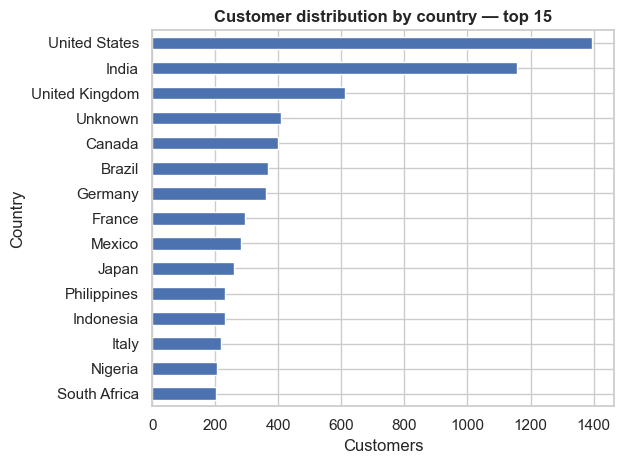

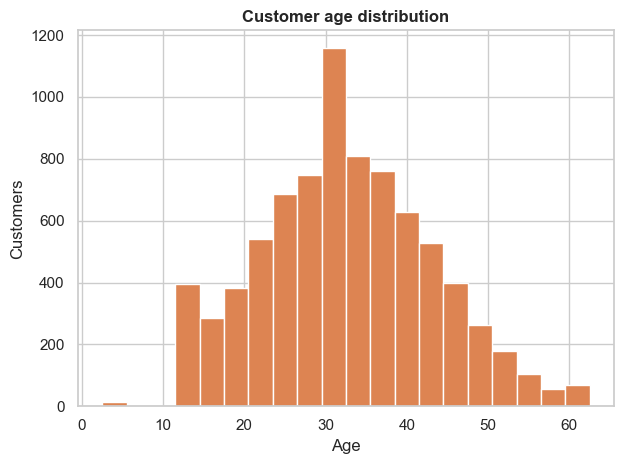

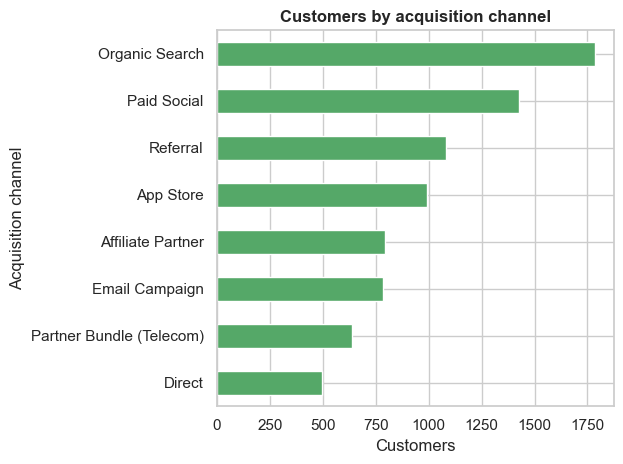

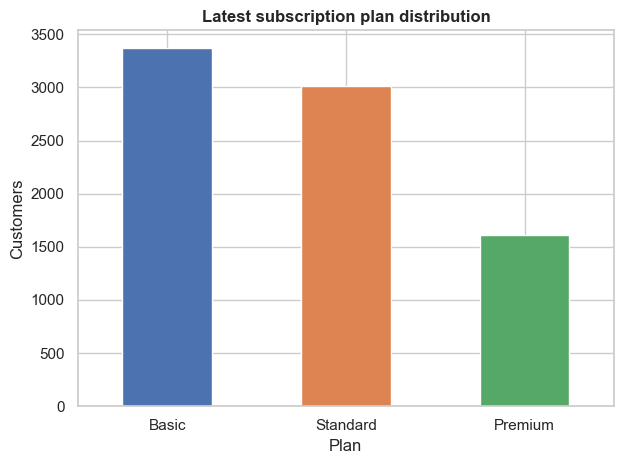

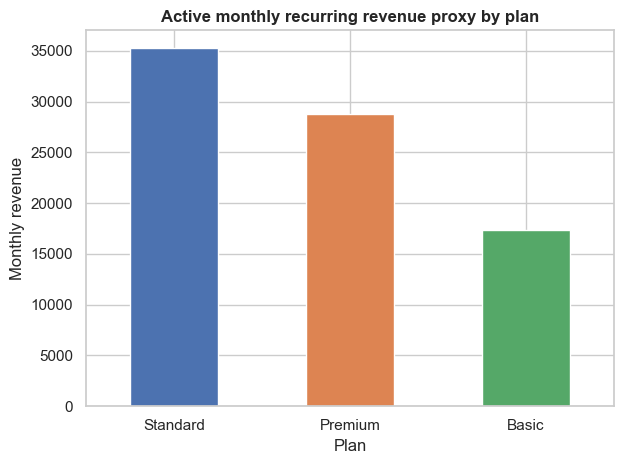

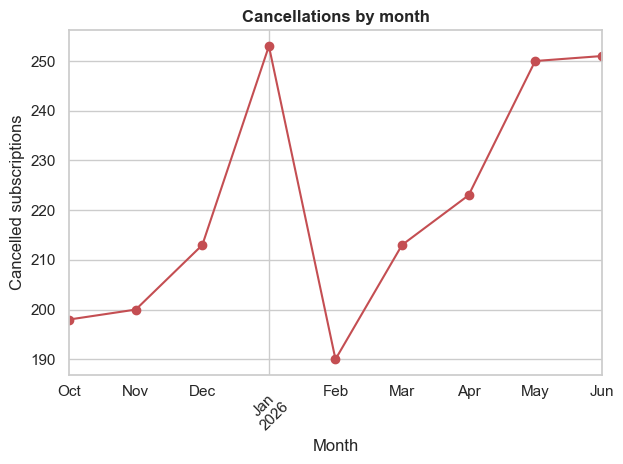

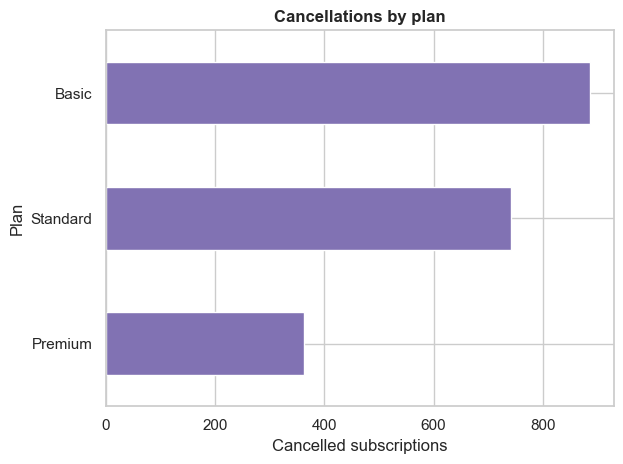

In [2]:
def finish_plot(title, xlabel=None, ylabel=None, figsize=(10, 5), rotation=0):
    ax = plt.gca()
    ax.set_title(title, weight="bold")
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    if rotation:
        ax.tick_params(axis="x", labelrotation=rotation)
    plt.tight_layout()
    plt.show()
    plt.close()

# 1. Customer distribution by country (largest 15 markets).
customers["country"].value_counts().head(15).sort_values().plot(kind="barh", color=sns.color_palette()[0])
finish_plot("Customer distribution by country — top 15", "Customers", "Country")

# 2. Customer age distribution.
customers["age"].dropna().plot(kind="hist", bins=20, color=sns.color_palette()[1], edgecolor="white")
finish_plot("Customer age distribution", "Age", "Customers")

# 3. Customer acquisition channel.
customers["acquisition_channel"].value_counts().sort_values().plot(kind="barh", color=sns.color_palette()[2])
finish_plot("Customers by acquisition channel", "Customers", "Acquisition channel")

# 4. Current plan distribution (one latest subscription per customer).
customer_base["plan_name"].fillna("No subscription").value_counts().plot(
    kind="bar", color=sns.color_palette("deep"), rot=0)
finish_plot("Latest subscription plan distribution", "Plan", "Customers")

# 5. Active monthly recurring revenue mix by plan.
active = latest_subscription[latest_subscription["subscription_status"].astype(str).str.lower().eq("active")]
mrr_by_plan = active.groupby("plan_name")["monthly_price"].sum().sort_values(ascending=False)
mrr_by_plan.plot(kind="bar", color=sns.color_palette("deep"), rot=0)
finish_plot("Active monthly recurring revenue proxy by plan", "Plan", "Monthly revenue")

# 6. Cancellation volume over time.
cancelled = subscriptions.dropna(subset=["cancellation_date"]).copy()
cancellations_monthly = cancelled.set_index("cancellation_date").resample("MS").size()
cancellations_monthly.plot(kind="line", marker="o", color=sns.color_palette()[3])
finish_plot("Cancellations by month", "Month", "Cancelled subscriptions", rotation=45)

# 7. Cancellation volume by plan.
cancellation_plan = cancelled.merge(plans[["plan_id", "plan_name"]], on="plan_id", how="left")
cancellation_plan["plan_name"].value_counts().sort_values().plot(kind="barh", color=sns.color_palette()[4])
finish_plot("Cancellations by plan", "Cancelled subscriptions", "Plan")


## Viewing and device engagement


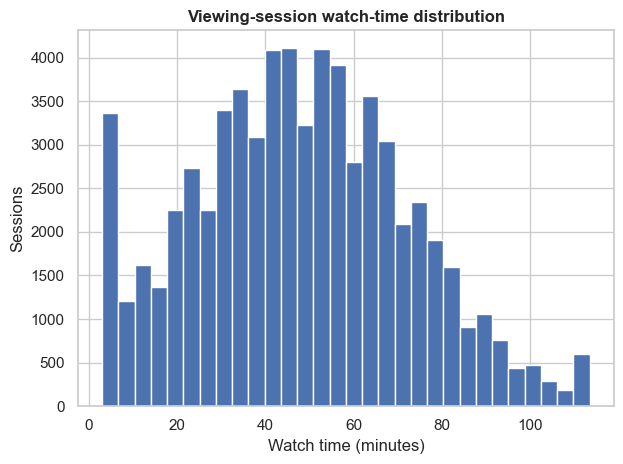

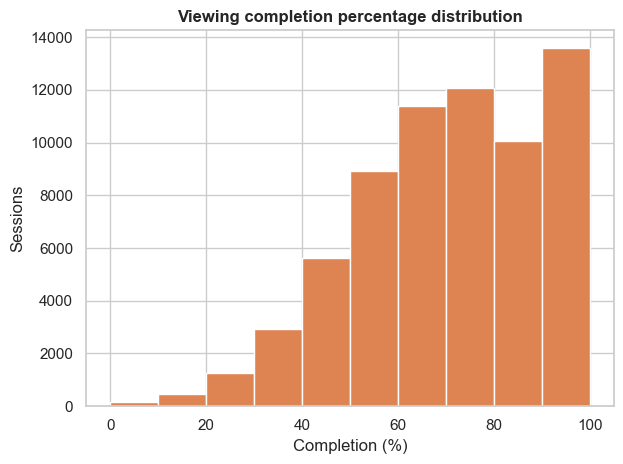

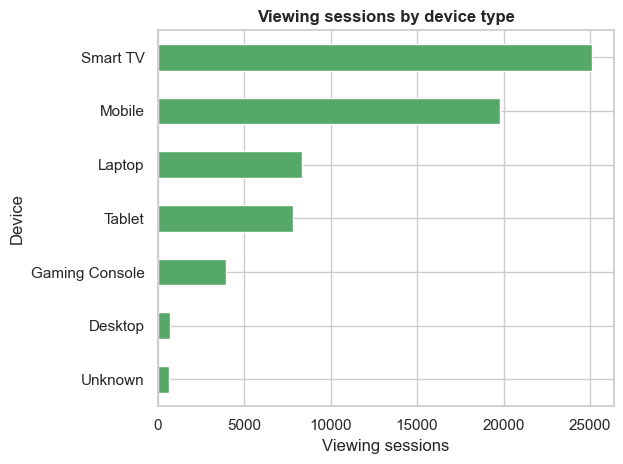

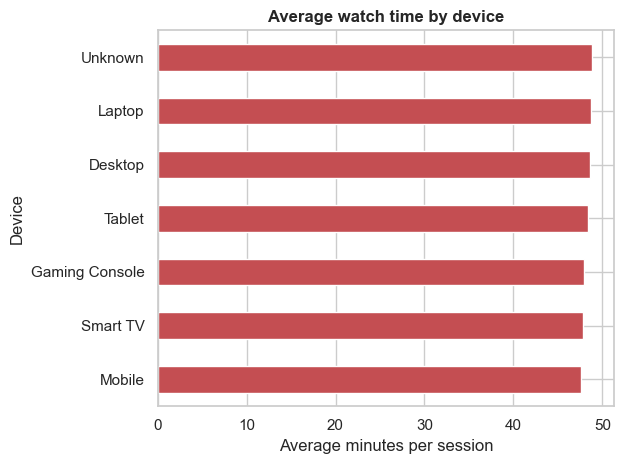

In [3]:
# 8. Watch-time distribution per viewing session.
viewing["watch_duration_minutes"].dropna().clip(lower=0).plot(
    kind="hist", bins=30, color=sns.color_palette()[0], edgecolor="white")
finish_plot("Viewing-session watch-time distribution", "Watch time (minutes)", "Sessions")

# 9. Completion percentage distribution.
viewing["completion_percentage"].dropna().clip(0, 100).plot(
    kind="hist", bins=np.arange(0, 110, 10), color=sns.color_palette()[1], edgecolor="white")
finish_plot("Viewing completion percentage distribution", "Completion (%)", "Sessions")

# 10. Device usage pattern.
viewing["device_type"].value_counts().sort_values().plot(kind="barh", color=sns.color_palette()[2])
finish_plot("Viewing sessions by device type", "Viewing sessions", "Device")

# 11. Average watch time by device.
viewing.groupby("device_type")["watch_duration_minutes"].mean().sort_values().plot(
    kind="barh", color=sns.color_palette()[3])
finish_plot("Average watch time by device", "Average minutes per session", "Device")


## Churn drivers


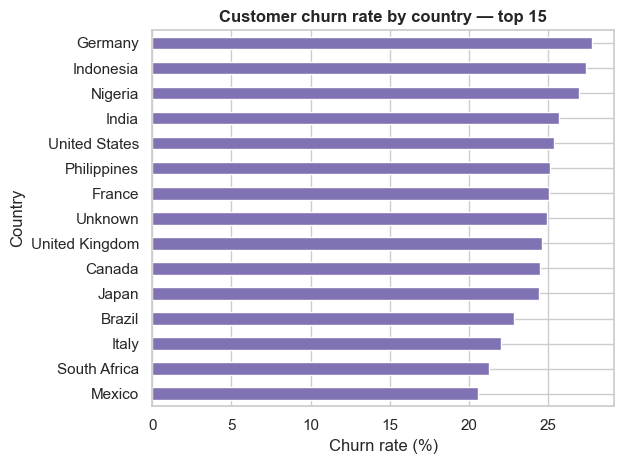

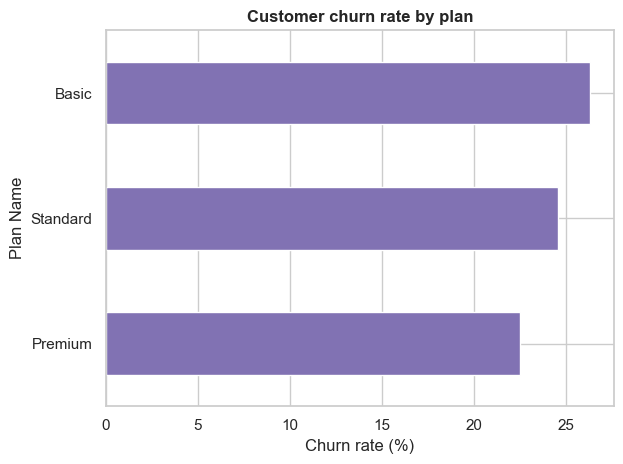

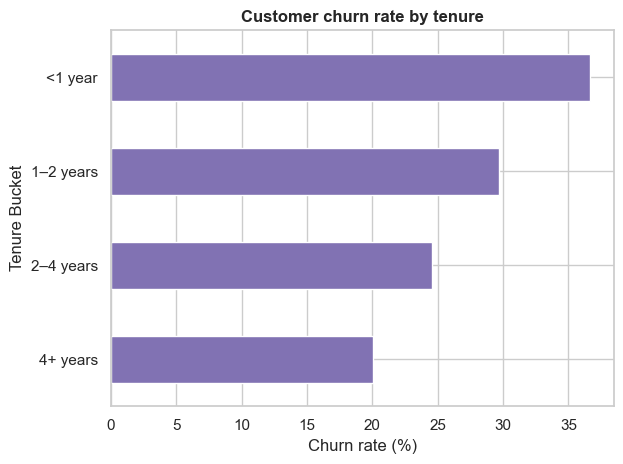

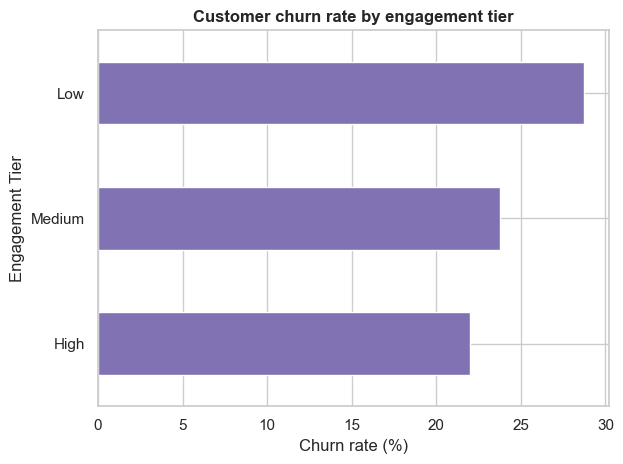

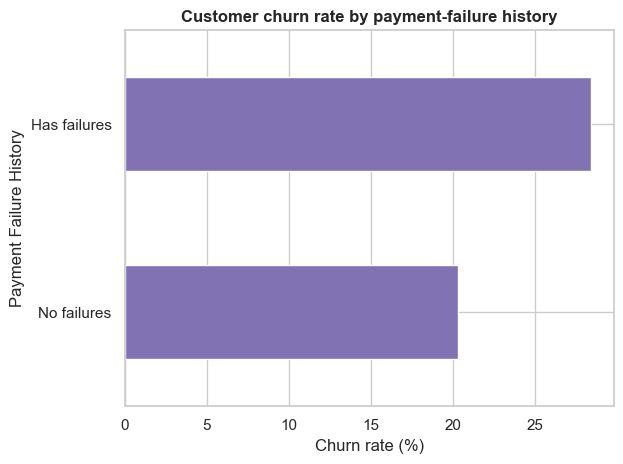

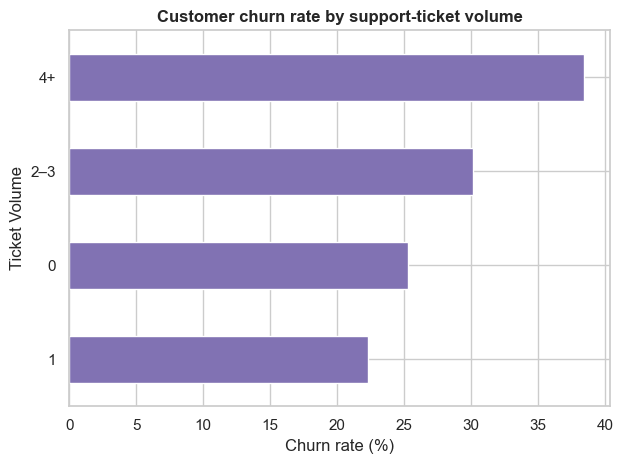

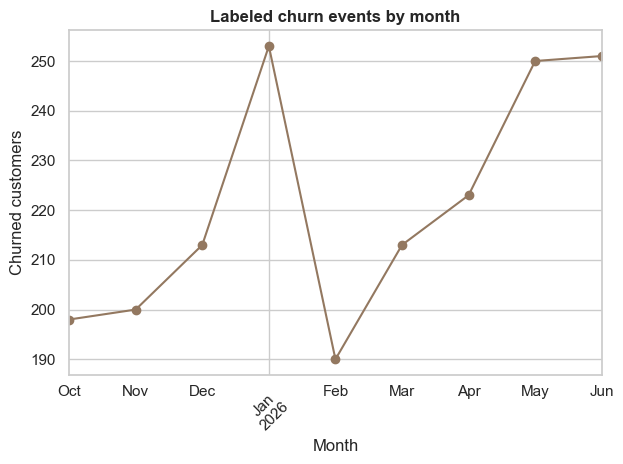

In [4]:
def churn_rate_chart(frame, category, title, top_n=None):
    grouped = frame.dropna(subset=[category, "churned"]).groupby(category, observed=True).agg(
        churn_rate=("churned", "mean"), customers=("customer_id", "size"))
    if top_n is not None:
        grouped = grouped.nlargest(top_n, "customers")
    grouped = grouped.sort_values("churn_rate")
    grouped["churn_rate"].mul(100).plot(kind="barh", color=sns.color_palette()[4])
    finish_plot(title, "Churn rate (%)", category.replace("_", " ").title())

# 12. Overall churn rate by country (top 15 countries by customer count).
churn_rate_chart(customer_base, "country", "Customer churn rate by country — top 15", top_n=15)

# 13. Churn rate by latest plan.
churn_rate_chart(customer_base, "plan_name", "Customer churn rate by plan")

# 14. Churn rate by customer tenure bucket.
churn_rate_chart(customer_base, "tenure_bucket", "Customer churn rate by tenure")

# 15. Churn rate by engagement tier.
churn_rate_chart(customer_base, "engagement_tier", "Customer churn rate by engagement tier")

# 16. Churn rate by payment-failure history.
churn_rate_chart(customer_base, "payment_failure_history", "Customer churn rate by payment-failure history")

# 17. Churn rate by support-ticket volume.
churn_rate_chart(customer_base, "ticket_volume", "Customer churn rate by support-ticket volume")

# 18. Labeled churn events by month.
churn_events = churn.loc[churn["churned"] & churn["churn_date"].notna()]
churn_events.set_index("churn_date").resample("MS").size().plot(
    kind="line", marker="o", color=sns.color_palette()[5])
finish_plot("Labeled churn events by month", "Month", "Churned customers", rotation=45)


## Support tickets, complaints, and satisfaction


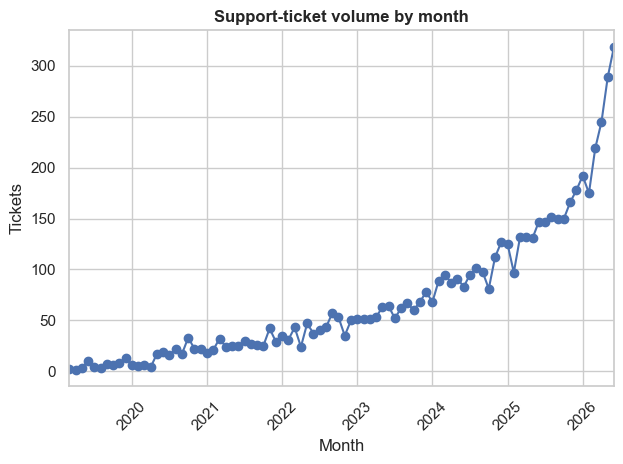

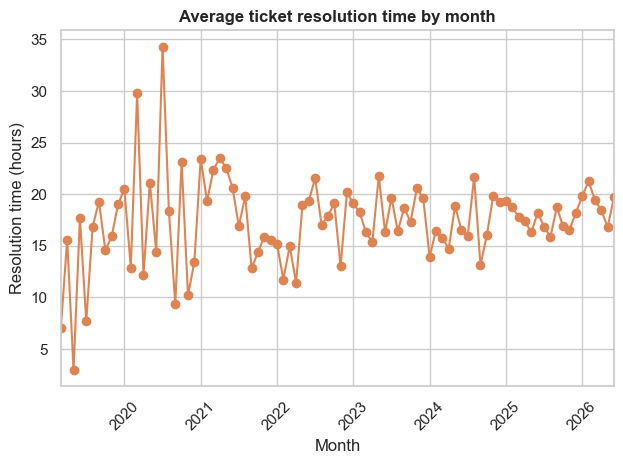

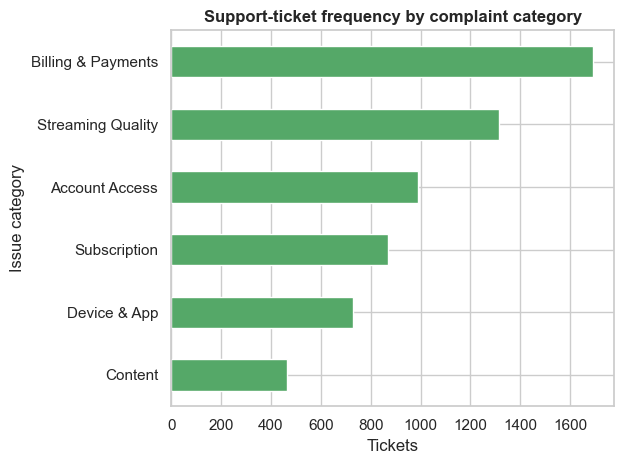

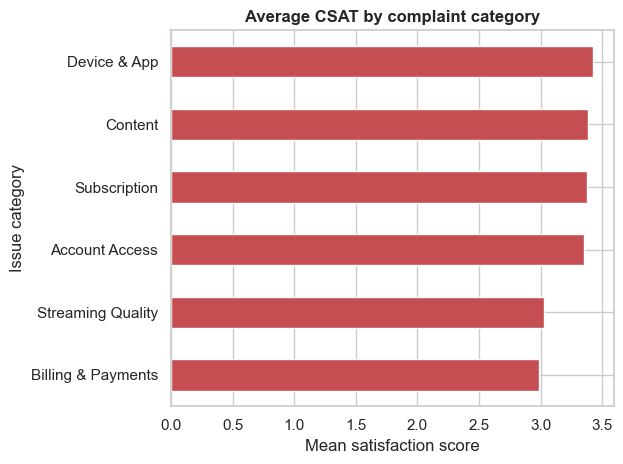

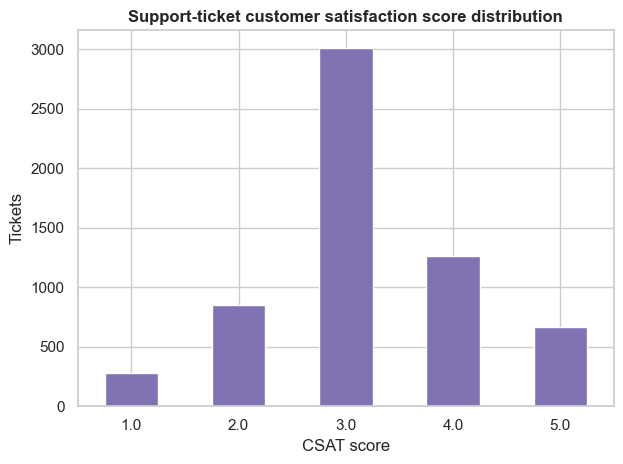

In [5]:
# 19. Monthly support-ticket volume.
ticket_monthly = tickets.dropna(subset=["ticket_date"]).set_index("ticket_date").resample("MS").size()
ticket_monthly.plot(kind="line", marker="o", color=sns.color_palette()[0])
finish_plot("Support-ticket volume by month", "Month", "Tickets", rotation=45)

# 20. Monthly mean resolution time.
resolution_monthly = (tickets.dropna(subset=["ticket_date", "resolution_time_hours"])
                     .set_index("ticket_date")["resolution_time_hours"].resample("MS").mean())
resolution_monthly.plot(kind="line", marker="o", color=sns.color_palette()[1])
finish_plot("Average ticket resolution time by month", "Month", "Resolution time (hours)", rotation=45)

# 21. Complaint/support issue category frequency.
tickets["issue_category"].value_counts().sort_values().plot(kind="barh", color=sns.color_palette()[2])
finish_plot("Support-ticket frequency by complaint category", "Tickets", "Issue category")

# 22. Relationship between issue category and average CSAT.
category_csat = (tickets.dropna(subset=["issue_category", "customer_satisfaction_score"])
                 .groupby("issue_category")["customer_satisfaction_score"].mean().sort_values())
category_csat.plot(kind="barh", color=sns.color_palette()[3])
finish_plot("Average CSAT by complaint category", "Mean satisfaction score", "Issue category")

# 23. Customer satisfaction score distribution across support tickets.
tickets["customer_satisfaction_score"].dropna().value_counts().sort_index().plot(
    kind="bar", color=sns.color_palette()[4], rot=0)
finish_plot("Support-ticket customer satisfaction score distribution", "CSAT score", "Tickets")
